# Junção das bases
Junta as 3 bases da Economatica (`Economatica-...csv`, `extra.csv`, `juros_pagaos_&_capex.csv`) em um único DataFrame, usando `Ativo` + `Data` como chave.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
arquivos = [
    'data/raw/economatica/Economatica-8900590473-20261020215038.csv',
    'data/raw/economatica/extra.csv',
    'data/raw/economatica/juros_pagaos_&_capex.csv',
]

# Economatica exporta em latin-1 e usa "-" para valor ausente
bases = [pd.read_csv(f, encoding='latin-1', na_values='-') for f in arquivos]
for f, b in zip(arquivos, bases):
    print(f, b.shape)

data/raw/economatica/Economatica-8900590473-20261020215038.csv (19856, 20)
data/raw/economatica/extra.csv (19294, 5)
data/raw/economatica/juros_pagaos_&_capex.csv (19294, 4)


In [3]:
# Nomes de coluna mais curtos (o original vem com o texto todo do Economatica)
nomes = {
    'DesFin': 'desp_financeira',
    'Ebitda/Fin': 'ebitda_desp_fin',
    'Ativo Tot': 'ativo_total',
    'Div Tt Bruta': 'divida_bruta',
    'Div Tt Lq': 'divida_liquida',
    'Patrim Liq': 'patrimonio_liquido',
    'LiqCor': 'liquidez_corrente',
    'CaixaEEqCx': 'caixa',
    'TotEmFiCP': 'emprestimos_cp',
    'TotEmFiLP': 'emprestimos_lp',
    'ResLuc': 'reservas_lucro',
    'AtvCir': 'ativo_circulante',
    'PasCir': 'passivo_circulante',
    'Receita': 'receita',
    'Valor Mercado': 'valor_mercado',
    'Pas+PL': 'passivo_mais_pl',
    'EBIT': 'ebit',
    'EBITDA': 'ebitda',
    'Lucro Liquido': 'lucro_liquido_12m',
    'CxOper': 'caixa_operacional_12m',
    'Div Moed Estr': 'divida_moeda_estrangeira',
    'JurosPagos': 'juros_pagos',
    'Capex (exc inv)': 'capex_12m',
}

def renomear(df):
    return df.rename(columns=lambda c: nomes.get(c.split('|')[0].strip(), c))

bases = [renomear(b) for b in bases]

In [4]:
# Junta as 3 bases pela chave Ativo + Data.
# how='outer' para não perder nenhuma linha (a base principal tem alguns trimestres de 2026 a mais)
df = bases[0]
for b in bases[1:]:
    df = df.merge(b, on=['Ativo', 'Data'], how='outer')

# CxOper e JurosPagos vêm em reais (não em milhares) -> padroniza para milhares como o resto
df['caixa_operacional_12m'] = df['caixa_operacional_12m'] / 1000
df['juros_pagos'] = df['juros_pagos'] / 1000

# Ticker limpo ("PETR4<XBSP>" -> "PETR4") e colunas de ano/trimestre para ordenar
df['Ativo'] = df['Ativo'].str.replace(r'<.*>', '', regex=True)
df['ano'] = df['Data'].str[2:].astype(int)
df['trimestre'] = df['Data'].str[0].astype(int)

df = df.sort_values(['Ativo', 'ano', 'trimestre']).reset_index(drop=True)
df = df[['Ativo', 'Data', 'ano', 'trimestre'] + [c for c in df.columns if c not in ('Ativo', 'Data', 'ano', 'trimestre')]]

print(df.shape)
df.head()

(20044, 27)


,Ativo,Data,ano,trimestre,desp_financeira,ebitda_desp_fin,ativo_total,divida_bruta,divida_liquida,patrimonio_liquido,...,receita,valor_mercado,passivo_mais_pl,ebit,ebitda,lucro_liquido_12m,caixa_operacional_12m,divida_moeda_estrangeira,juros_pagos,capex_12m
0,AALR3,1T2010,2010,1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AALR3,2T2010,2010,2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AALR3,3T2010,2010,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AALR3,4T2010,2010,4,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AALR3,1T2011,2011,1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Quantidade de valores ausentes por coluna
df.isna().sum()

Ativo                           0
Data                            0
ano                             0
trimestre                       0
desp_financeira              5621
ebitda_desp_fin              6277
ativo_total                  5217
divida_bruta                 5227
divida_liquida               5227
patrimonio_liquido           5217
liquidez_corrente            5219
caixa                        5727
emprestimos_cp               5227
emprestimos_lp               5224
reservas_lucro               5219
ativo_circulante             5218
passivo_circulante           5218
receita                      5219
valor_mercado                6016
passivo_mais_pl              5217
ebit                         5694
ebitda                       6323
lucro_liquido_12m            5614
caixa_operacional_12m        5685
divida_moeda_estrangeira    19559
juros_pagos                 20044
capex_12m                   20044
dtype: int64

In [6]:
# Só a Petrobras
petr = df[df['Ativo'].str.startswith('PETR')]
petr.head()

,Ativo,Data,ano,trimestre,desp_financeira,ebitda_desp_fin,ativo_total,divida_bruta,divida_liquida,patrimonio_liquido,...,receita,valor_mercado,passivo_mais_pl,ebit,ebitda,lucro_liquido_12m,caixa_operacional_12m,divida_moeda_estrangeira,juros_pagos,capex_12m
14264,PETR4,1T2010,2010,1,884306.0,15.973850,365998064.0,107492992.0,80541666.0,170299082.0,...,50412070.0,3.323807e+08,365998064.0,46982879.0,61812674.0,30892210.0,49155511.0,58327551.0,NaN,NaN
14265,PETR4,2T2010,2010,2,1699840.0,17.110247,382029847.0,117772644.0,93562778.0,176974123.0,...,104043449.0,2.566753e+08,382029847.0,45799117.0,60632211.0,31452705.0,53273776.0,62558769.0,NaN,NaN
14266,PETR4,3T2010,2010,3,2636887.0,17.434963,507697010.0,114660168.0,67368235.0,297360982.0,...,158782492.0,3.737660e+08,507697010.0,46844485.0,61995737.0,32716589.0,51667059.0,61310794.0,NaN,NaN
14267,PETR4,4T2010,2010,4,3311326.0,18.257237,519970003.0,117915312.0,61574756.0,306765182.0,...,213273669.0,3.802467e+08,519970003.0,45574588.0,60455664.0,35189366.0,53435437.0,NaN,NaN,NaN
14268,PETR4,1T2011,2011,1,717834.0,22.805355,544945300.0,128999907.0,65639316.0,314781580.0,...,54800499.0,4.024871e+08,544945300.0,47526001.0,62700352.0,38448055.0,56682786.0,NaN,NaN,NaN


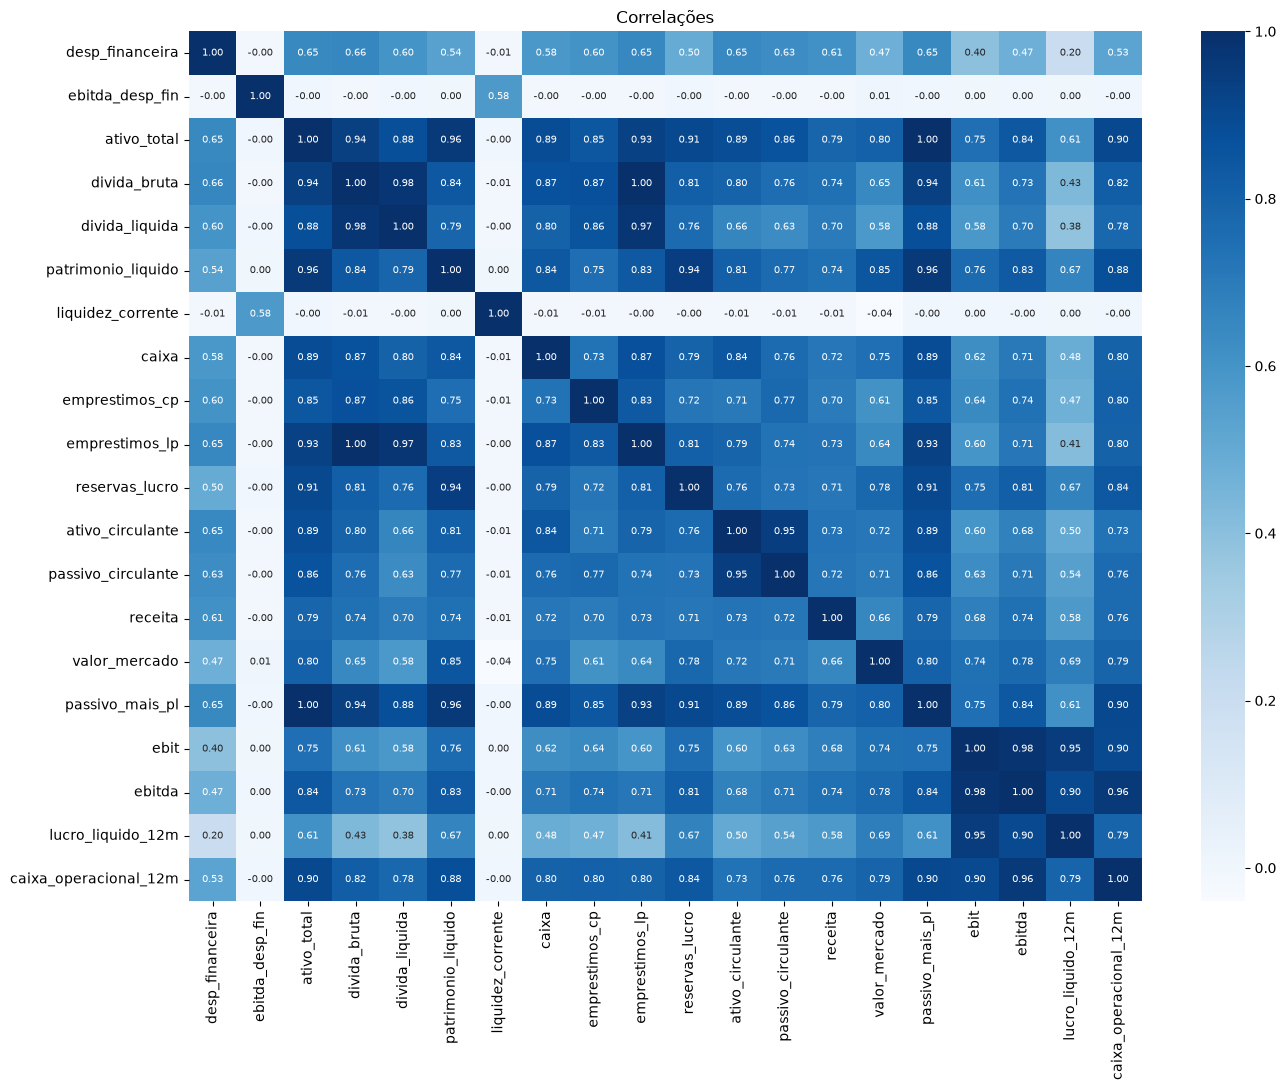

In [7]:
# juros_pagos e capex_12m ficam de fora (100% vazias), divida_moeda_estrangeira também (quase vazia)
variaveis = [
    'desp_financeira',
    'ebitda_desp_fin',
    'ativo_total',
    'divida_bruta',
    'divida_liquida',
    'patrimonio_liquido',
    'liquidez_corrente',
    'caixa',
    'emprestimos_cp',
    'emprestimos_lp',
    'reservas_lucro',
    'ativo_circulante',
    'passivo_circulante',
    'receita',
    'valor_mercado',
    'passivo_mais_pl',
    'ebit',
    'ebitda',
    'lucro_liquido_12m',
    'caixa_operacional_12m',
]

plt.figure(figsize=(14,11))

sns.heatmap(df[variaveis].corr(), annot=True, cmap='Blues', fmt='.2f', annot_kws={'size': 7})
plt.title('Correlações')
plt.tight_layout()
plt.show()